# Tasks - Lab 7

### Task 3.1: MP Data Ingestion, Featurization, Variance Pruning, Correlation Check & Scaling

/Users/dshevchenko/git-personal/materials-labs/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Retrieved 300 SummaryDoc documents in 3.3s

ElementProperty: 100%|██████████| 247/247 [00:04<00:00, 49.83it/s] 


Total NaN values in X: 0 | in y: 0
Dropped low-variance / mostly-zero cols (14): ['MagpieData maximum NsValence', 'MagpieData minimum GSbandgap', 'MagpieData minimum GSmagmom', 'MagpieData minimum NdUnfilled', 'MagpieData minimum NdValence', 'MagpieData minimum NfUnfilled', 'MagpieData minimum NfValence', 'MagpieData minimum NsUnfilled', 'MagpieData mode GSmagmom', 'MagpieData mode NdUnfilled', 'MagpieData mode NdValence', 'MagpieData mode NfUnfilled', 'MagpieData mode NfValence', 'MagpieData mode NsUnfilled']
High-correlation pairs (|r| >= 0.9): 120
Redundant cols to drop (65): ['MagpieData range Number', 'MagpieData range MendeleevNumber', 'MagpieData avg_dev MendeleevNumber', 'MagpieData minimum AtomicWeight', 'MagpieData maximum AtomicWeight', 'MagpieData range AtomicWeight', 'MagpieData mean AtomicWeight', 'MagpieData avg_dev AtomicWeight', 'MagpieData mode AtomicWeight', 'MagpieData range MeltingT', 'MagpieData avg_dev MeltingT', 'MagpieData maximum Column', 'MagpieData range Col

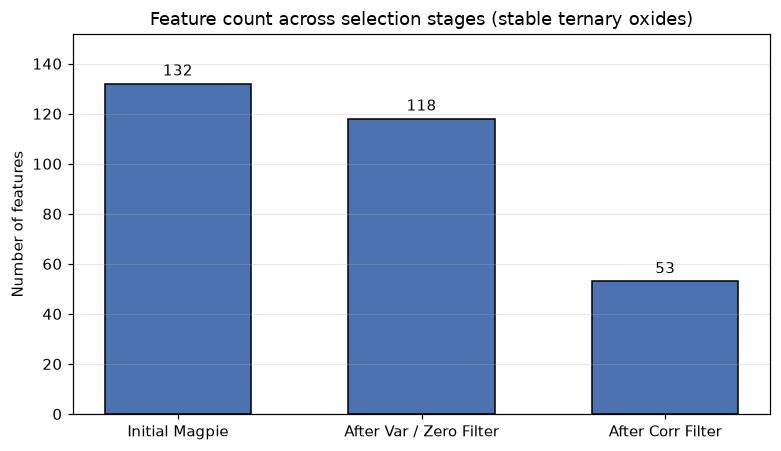

In [1]:
# ==============================================================================
# TASK 3.1: STUDENT STARTER CODE
# ==============================================================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mp_api.client import MPRester
from matminer.featurizers.composition import ElementProperty
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from dotenv import load_dotenv

# Resolve MP API key if not already defined in notebook
load_dotenv()
if not (API_KEY := os.getenv("MP_API_KEY", None)):
    raise ValueError("MP_API_KEY not found in environment variables. Please set it in your .env file or system environment.")

# --- 1. QUERY MATERIALS PROJECT & FEATURIZE COMPOSITIONS ---
target_fields = ["material_id", "formula_pretty", "composition", "is_stable"]

# : Query summary endpoint for stable ternary oxides (elements=["O"], num_elements=3, is_stable=True)
# : Limit retrieved records using chunk_size & num_chunks (and/or slicing docs[:250]),
# since mp-api does not use a single `limit` argument (e.g., chunk_size=100, num_chunks=3 -> up to 300 docs)
with MPRester(API_KEY) as mpr:
    docs = mpr.materials.summary.search(
        elements= ["O"],
        num_elements= 3,
        is_stable= True,
        fields= target_fields,
        chunk_size=100,
        num_chunks=3
    )
docs = docs[:250]

# : Build DataFrame, deduplicate by 'formula_pretty', and featurize 'composition' with Magpie
df_raw = pd.DataFrame([{f: getattr(doc, f) for f in target_fields} for doc in docs])
df_dedup = df_raw.drop_duplicates(subset="formula_pretty", keep="first").reset_index(drop=True)
featurizer = ElementProperty.from_preset("magpie", impute_nan=False)
df_feat = featurizer.featurize_dataframe(df_dedup, col_id="composition", ignore_errors=True)

# --- 2. AUDIT NaN VALUES, DEFINE X & y, AND SPLIT WITHOUT LEAKAGE ---
feature_cols = featurizer.feature_labels()
X = df_feat[feature_cols].copy()
y = df_feat["is_stable"].astype(int).copy()

# : Check NaN counts in X and y; drop rows with any NaN if present
nan_x_total = X.isna().sum().sum()
nan_y_total = y.isna().sum()
print(f"Total NaN values in X: {nan_x_total} | in y: {nan_y_total}")
if nan_x_total or nan_y_total:
    valid_mask = X.notna().all(axis=1) & y.notna()
    X, y = X[valid_mask].copy(), y[valid_mask].copy()
    print(f"Dropped {(~valid_mask).sum()} incomplete rows -> {len(X)} rows remain")

# : Split X and y (80% train / 20% test, random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 3. PRUNE LOW-VARIANCE & MOSTLY-ZERO FEATURES ON X_TRAIN ONLY ---
# : Fit VarianceThreshold(threshold=1e-4) on X_train ONLY
selector = VarianceThreshold(threshold=1e-4).fit(X_train)
# ~selector.get_support() inverts the boolean mask (True -> False, False -> True)
# to select columns that failed the variance threshold (candidates to drop)
low_var_cols = list(X_train.columns[~selector.get_support()])

# : Identify columns in X_train with > 95% zero values
mostly_zero_cols = list(X_train.columns[(X_train == 0).mean() > 0.95])

low_info_cols = sorted(set(low_var_cols + mostly_zero_cols))

# Drop low-information columns from X_train AND identically from X_test
X_train_v1 = X_train.drop(columns=low_info_cols).copy()
X_test_v1 = X_test.drop(columns=low_info_cols).copy()
print(f"Dropped low-variance / mostly-zero cols ({len(low_info_cols)}): {low_info_cols}")

# --- 4. CORRELATION SCREENING ON X_TRAIN_V1 & REDUNDANCY PRUNING ---
# : Compute correlation matrix on X_train_v1 ONLY (Pearson or Spearman)
corr_matrix = X_train_v1.corr(method='pearson')

# : Find feature pairs in upper triangle with |corr| >= 0.90 and list redundant cols
corr_threshold = 0.90
high_corr_pairs = []
cols_to_drop_corr = []
upper = corr_matrix.abs().where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
for col in upper.columns:
    for row in upper.index[upper[col] >= corr_threshold]:
        high_corr_pairs.append((row, col, corr_matrix.loc[row, col]))
        # keep the earlier feature (row), drop the later one (col)
        if col not in cols_to_drop_corr:
            cols_to_drop_corr.append(col)
print(f"High-correlation pairs (|r| >= {corr_threshold}): {len(high_corr_pairs)}")
print(f"Redundant cols to drop ({len(cols_to_drop_corr)}): {cols_to_drop_corr}")

X_train_sel = X_train_v1.drop(columns=cols_to_drop_corr).copy()
X_test_sel = X_test_v1.drop(columns=cols_to_drop_corr).copy()
print(f"Pruned shapes -> X_train_sel: {X_train_sel.shape}, X_test_sel: {X_test_sel.shape}")

# --- 5. FIT STANDARDSCALER ON X_TRAIN_SEL ONLY & TRANSFORM BOTH SETS ---
# : Fit StandardScaler on X_train_sel ONLY, then transform X_train_sel and X_test_sel
scaler = StandardScaler().fit(X_train_sel)
X_train_scaled = scaler.transform(X_train_sel)
X_test_scaled = scaler.transform(X_test_sel)

# --- 6. VISUALIZE FEATURE COUNT ACROSS SELECTION STAGES ---
stage_labels = ["Initial Magpie", "After Var / Zero Filter", "After Corr Filter"]
stage_counts = [X_train.shape[1], X_train_v1.shape[1], X_train_sel.shape[1]]

fig, ax = plt.subplots(figsize=(7.2, 4.2), dpi=110)
# : Plot a bar chart of stage_counts across stage_labels and annotate bar values
bars = ax.bar(stage_labels, stage_counts, color="#4C72B0", edgecolor="black", width=0.6)
ax.bar_label(bars, labels=[str(c) for c in stage_counts], padding=3)
ax.set_ylabel("Number of features")
ax.set_title("Feature count across selection stages (stable ternary oxides)")
ax.set_ylim(0, max(stage_counts) * 1.15)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Task 3.2: Leakage-Free Feature Selection, `StandardScaler` & Artifact Checkpoints

In [2]:
# ==============================================================================
# TASK 3.2: STUDENT STARTER CODE
# ==============================================================================
import os
import joblib
import numpy as np
import pandas as pd
from mp_api.client import MPRester
from matminer.featurizers.composition import ElementProperty
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

try:
    API_KEY
except NameError:
    try:
        from google.colab import userdata
        API_KEY = userdata.get("MP-Key")
    except (ImportError, KeyError):
        API_KEY = os.environ.get("MP_API_KEY", "YOUR_API_KEY_HERE")

# --- 1. QUERY MATERIALS PROJECT & FEATURIZE COMPOSITIONS ---
target_fields = ["material_id", "formula_pretty", "composition", "is_stable"]

# : Query summary endpoint for ternary sulfides (elements=["S"], num_elements=3)
# : Control sample count via chunk_size / num_chunks and/or docs[:250] (e.g., chunk_size=100, num_chunks=3 -> up to 300 docs)
with MPRester(API_KEY) as mpr:
    docs = mpr.materials.summary.search(
        elements=["S"],
        num_elements=3,
        fields=target_fields,
        chunk_size=100,
        num_chunks=3
    )
docs = docs[:250]

# : Build DataFrame, deduplicate by 'formula_pretty', and featurize with Magpie
df_raw = pd.DataFrame([{f: getattr(doc, f) for f in target_fields} for doc in docs])
df_dedup = df_raw.drop_duplicates(subset="formula_pretty", keep="first").reset_index(drop=True)
featurizer = ElementProperty.from_preset("magpie", impute_nan=False)
df_feat = featurizer.featurize_dataframe(df_dedup, col_id="composition", ignore_errors=True)

# --- 2. AUDIT NaN VALUES & SPLIT WITHOUT DATA LEAKAGE ---
feature_cols = featurizer.feature_labels()
X = df_feat[feature_cols].copy()
y = df_feat["is_stable"].astype(int).copy()

# : Audit NaN values in X and y; drop incomplete rows if any exist
nan_x_total = X.isna().sum().sum()
nan_y_total = y.isna().sum()
print(f"NaN audit -> X: {nan_x_total}, y: {nan_y_total}")
if nan_x_total or nan_y_total:
    valid_mask = X.notna().all(axis=1) & y.notna()
    X, y = X[valid_mask].copy(), y[valid_mask].copy()
    print(f"Dropped {(~valid_mask).sum()} incomplete rows -> {len(X)} rows remain")
print(f"Class balance (is_stable): {y.value_counts().to_dict()}")

# : Split 80% train / 20% test with random_state=42 and stratification
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# --- 3. PRUNE LOW-VARIANCE & MOSTLY-ZERO FEATURES ON X_TRAIN ONLY ---
# : Fit VarianceThreshold(threshold=1e-4) on X_train ONLY
selector = VarianceThreshold(threshold=1e-4).fit(X_train)
# ~selector.get_support() inverts the boolean mask (True -> False, False -> True)
# to select columns that failed the variance threshold (candidates to drop)
low_var_cols = list(X_train.columns[~selector.get_support()])

# : Identify columns in X_train with > 95% zeros
mostly_zero_cols = list(X_train.columns[(X_train == 0).mean() > 0.95])

low_info_cols = sorted(set(low_var_cols + mostly_zero_cols))

# Drop identical low-information columns from X_train and X_test
X_train_v1 = X_train.drop(columns=low_info_cols).copy()
X_test_v1 = X_test.drop(columns=low_info_cols).copy()
print(f"Dropped low-variance / mostly-zero cols ({len(low_info_cols)}): {low_info_cols}")

# --- 4. CORRELATION CHECK ON X_TRAIN_V1 & REDUNDANCY REMOVAL ---
# : Compute correlation matrix on X_train_v1 ONLY and detect |r| >= 0.90 pairs
corr_matrix = X_train_v1.corr(method="pearson")
corr_threshold = 0.90
high_corr_pairs = []
cols_to_drop_corr = []
upper = corr_matrix.abs().where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
for col in upper.columns:
    for row in upper.index[upper[col] >= corr_threshold]:
        high_corr_pairs.append((row, col, corr_matrix.loc[row, col]))
        # keep the earlier feature (row), drop the later one (col)
        if col not in cols_to_drop_corr:
            cols_to_drop_corr.append(col)
print(f"High-correlation pairs (|r| >= {corr_threshold}): {len(high_corr_pairs)}")
print(f"Redundant cols to drop ({len(cols_to_drop_corr)}): {cols_to_drop_corr}")

X_train_sel = X_train_v1.drop(columns=cols_to_drop_corr).copy()
X_test_sel = X_test_v1.drop(columns=cols_to_drop_corr).copy()
print(f"Selected shapes -> X_train_sel: {X_train_sel.shape}, X_test_sel: {X_test_sel.shape}")

# --- 5. FIT STANDARDSCALER ON X_TRAIN_SEL ONLY & TRANSFORM BOTH SETS ---
# : Fit StandardScaler on X_train_sel ONLY and transform X_train_sel and X_test_sel
scaler = StandardScaler().fit(X_train_sel)
X_train_scaled = scaler.transform(X_train_sel)
X_test_scaled = scaler.transform(X_test_sel)

# --- 6. PERSIST ARTIFACTS & VERIFY RELOAD (INCLUDING pd.read_csv) ---
# : Save scaled arrays (.npy), scaler (.joblib), and summary CSV (index=False)
artifact_dir = "artifacts_task_3_2"
os.makedirs(artifact_dir, exist_ok=True)
x_train_path = os.path.join(artifact_dir, "X_train_scaled.npy")
x_test_path = os.path.join(artifact_dir, "X_test_scaled.npy")
scaler_path = os.path.join(artifact_dir, "fitted_scaler.joblib")
summary_path = os.path.join(artifact_dir, "curated_sulfide_summary.csv")

np.save(x_train_path, X_train_scaled)
np.save(x_test_path, X_test_scaled)
joblib.dump(scaler, scaler_path)

meta_cols = ["material_id", "formula_pretty"]
summary_train = df_feat.loc[X_train_sel.index, meta_cols].assign(split="train", is_stable=y_train)
summary_test = df_feat.loc[X_test_sel.index, meta_cols].assign(split="test", is_stable=y_test)
df_summary = pd.concat(
    [pd.concat([summary_train, X_train_sel], axis=1), pd.concat([summary_test, X_test_sel], axis=1)]
).reset_index(drop=True)
df_summary["material_id"] = df_summary["material_id"].astype(str)
df_summary.to_csv(summary_path, index=False)
print(f"Saved artifacts to '{artifact_dir}/': {sorted(os.listdir(artifact_dir))}")

# : Reload CSV via pd.read_csv, scaled array via np.load, and scaler via joblib.load
df_reloaded = pd.read_csv(summary_path)
X_train_reloaded = np.load(x_train_path)
scaler_reloaded = joblib.load(scaler_path)

assert np.allclose(X_train_reloaded, X_train_scaled)
assert np.allclose(scaler_reloaded.transform(X_test_sel), X_test_scaled)
assert df_reloaded.shape == df_summary.shape
print(f"Reloaded shapes -> X_train_reloaded: {X_train_reloaded.shape}, df_reloaded: {df_reloaded.shape}")

✓ Retrieved 300 SummaryDoc documents in 1.3s

ElementProperty: 100%|██████████| 156/156 [00:01<00:00, 79.84it/s]


NaN audit -> X: 0, y: 0
Class balance (is_stable): {0: 109, 1: 47}
Dropped low-variance / mostly-zero cols (13): ['MagpieData maximum NsValence', 'MagpieData minimum GSbandgap', 'MagpieData minimum GSmagmom', 'MagpieData minimum NdUnfilled', 'MagpieData minimum NdValence', 'MagpieData minimum NfUnfilled', 'MagpieData minimum NfValence', 'MagpieData minimum NsUnfilled', 'MagpieData mode GSmagmom', 'MagpieData mode NdUnfilled', 'MagpieData mode NfUnfilled', 'MagpieData mode NfValence', 'MagpieData mode NsUnfilled']
High-correlation pairs (|r| >= 0.9): 98
Redundant cols to drop (56): ['MagpieData range Number', 'MagpieData avg_dev Number', 'MagpieData range MendeleevNumber', 'MagpieData avg_dev MendeleevNumber', 'MagpieData minimum AtomicWeight', 'MagpieData maximum AtomicWeight', 'MagpieData range AtomicWeight', 'MagpieData mean AtomicWeight', 'MagpieData avg_dev AtomicWeight', 'MagpieData mode AtomicWeight', 'MagpieData range MeltingT', 'MagpieData avg_dev MeltingT', 'MagpieData maximum

### Task 3.3 (*): Continuous-Target Pipeline, Histogram Overlap Check, Before/After Correlation Matrices, `StandardScaler` & Artifact Verification

✓ Retrieved 1,000 SummaryDoc documents in 8.9s

ElementProperty: 100%|██████████| 550/550 [00:06<00:00, 78.91it/s] 


Records -> raw: 1000, deduplicated: 550
NaN audit -> X: 0, y: 0
y_train -> mean: -1.5998, median: -1.4960, min: -4.3427, max: 1.3102 (eV/atom)
 y_test -> mean: -1.5998, median: -1.4927, min: -4.3304, max: 0.3451 (eV/atom)


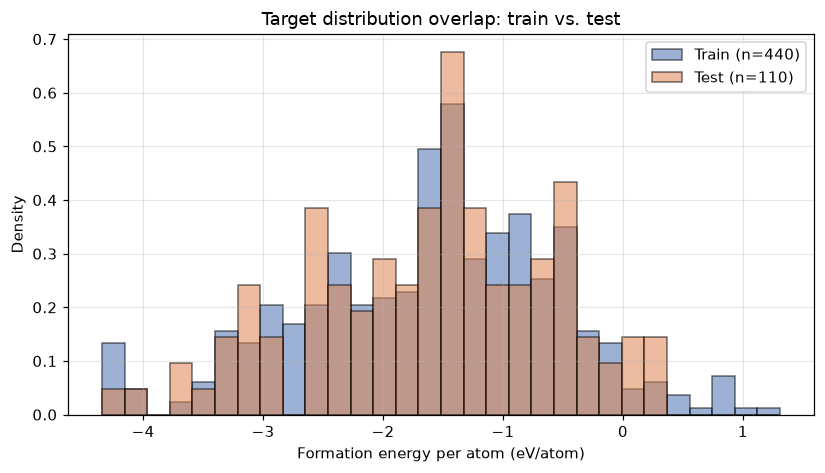

Dropped low-variance / mostly-zero cols (11): ['MagpieData maximum NsValence', 'MagpieData minimum GSbandgap', 'MagpieData minimum GSmagmom', 'MagpieData minimum NdUnfilled', 'MagpieData minimum NdValence', 'MagpieData minimum NfUnfilled', 'MagpieData minimum NfValence', 'MagpieData minimum NsUnfilled', 'MagpieData mode GSmagmom', 'MagpieData mode NfUnfilled', 'MagpieData mode NfValence']


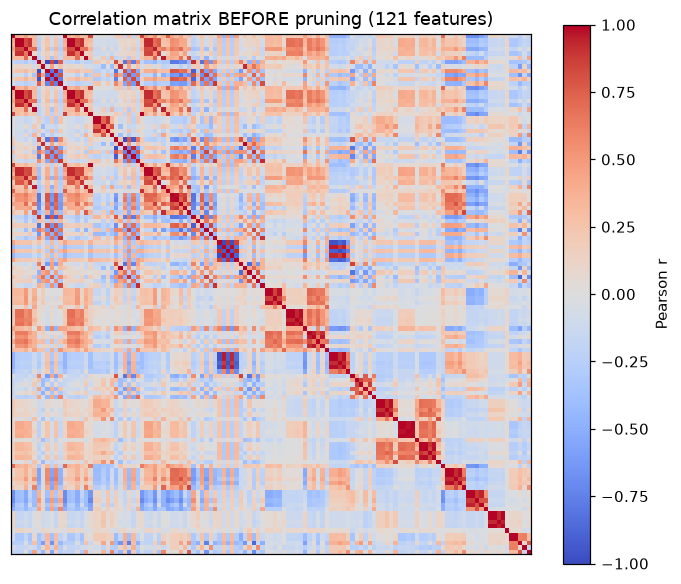

High-correlation pairs (|r| >= 0.9): 120
Redundant cols to drop (60): ['MagpieData range Number', 'MagpieData avg_dev Number', 'MagpieData range MendeleevNumber', 'MagpieData avg_dev MendeleevNumber', 'MagpieData minimum AtomicWeight', 'MagpieData maximum AtomicWeight', 'MagpieData range AtomicWeight', 'MagpieData mean AtomicWeight', 'MagpieData avg_dev AtomicWeight', 'MagpieData mode AtomicWeight', 'MagpieData range MeltingT', 'MagpieData avg_dev MeltingT', 'MagpieData maximum Column', 'MagpieData range Column', 'MagpieData avg_dev Column', 'MagpieData minimum Row', 'MagpieData maximum Row', 'MagpieData range Row', 'MagpieData mean Row', 'MagpieData avg_dev Row', 'MagpieData mode Row', 'MagpieData minimum CovalentRadius', 'MagpieData range CovalentRadius', 'MagpieData mode CovalentRadius', 'MagpieData minimum Electronegativity', 'MagpieData range Electronegativity', 'MagpieData range NsValence', 'MagpieData mean NsValence', 'MagpieData avg_dev NsValence', 'MagpieData mode NsValence', 

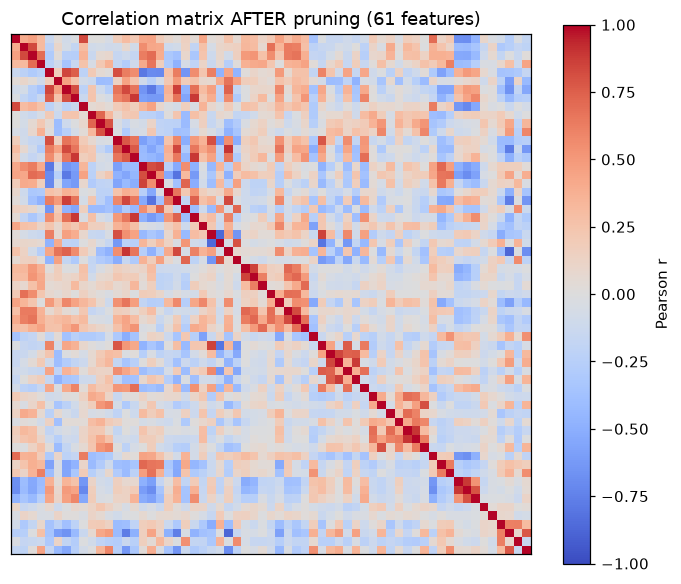

Saved artifacts to 'artifacts_task_3_3/': ['X_test_scaled.npy', 'X_train_scaled.npy', 'curated_regression_summary.csv', 'fitted_scaler.joblib', 'y_test.npy', 'y_train.npy']
All reload checks passed -> X_train: (440, 61), X_test: (110, 61), df_reloaded: (550, 65)


In [3]:
# ==============================================================================
# TASK 3.3 (*): STUDENT STARTER CODE
# ==============================================================================
import os
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mp_api.client import MPRester
from matminer.featurizers.composition import ElementProperty
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

try:
    API_KEY
except NameError:
    try:
        from google.colab import userdata
        API_KEY = userdata.get("MP-Key")
    except (ImportError, KeyError):
        API_KEY = os.environ.get("MP_API_KEY", "YOUR_API_KEY_HERE")

# --- 1. QUERY LARGER SAMPLE SET FROM MATERIALS PROJECT & FEATURIZE ---
target_fields = ["material_id", "formula_pretty", "composition", "formation_energy_per_atom"]

# : Query summary endpoint for ternary oxides (elements=["O"], num_elements=3)
# across multiple chunks (e.g., chunk_size=100, num_chunks=10 -> up to 1000 docs)
with MPRester(API_KEY) as mpr:
    docs = mpr.materials.summary.search(
        elements=["O"],
        num_elements=3,
        fields=target_fields,
        chunk_size=100,
        num_chunks=10
    )

# : Build DataFrame (up to 1000 valid records), deduplicate by 'formula_pretty',
# and featurize 'composition' with Magpie
df_raw = pd.DataFrame([{f: getattr(doc, f) for f in target_fields} for doc in docs])
df_raw = df_raw.dropna(subset=["composition", "formation_energy_per_atom"]).head(1000)
df_dedup = df_raw.drop_duplicates(subset="formula_pretty", keep="first").reset_index(drop=True)
featurizer = ElementProperty.from_preset("magpie", impute_nan=False)
df_feat = featurizer.featurize_dataframe(df_dedup, col_id="composition", ignore_errors=True)
print(f"Records -> raw: {len(df_raw)}, deduplicated: {len(df_dedup)}")

# --- 2. NaN AUDIT & QUANTILE-STRATIFIED SPLIT FOR CONTINUOUS TARGET ---
feature_cols = featurizer.feature_labels()
X = df_feat[feature_cols].copy()
y = df_feat["formation_energy_per_atom"].astype(float).copy()

# : Audit NaN values in X and y; drop rows with any NaN if present
nan_x_total = X.isna().sum().sum()
nan_y_total = y.isna().sum()
print(f"NaN audit -> X: {nan_x_total}, y: {nan_y_total}")
if nan_x_total or nan_y_total:
    valid_mask = X.notna().all(axis=1) & y.notna()
    X, y = X[valid_mask].copy(), y[valid_mask].copy()
    print(f"Dropped {(~valid_mask).sum()} incomplete rows -> {len(X)} rows remain")

# : Create temporary quantile bins (y_strata) via pd.qcut and split 80% / 20%
# (random_state=42, stratify=y_strata); keep y_train and y_test continuous
y_strata = pd.qcut(y, q=10, labels=False, duplicates="drop")
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y_strata
)

# --- 3. VISUAL OVERLAP CHECK: Y_TRAIN VS. Y_TEST HISTOGRAMS ---
# : Print mean, median, min, max of y_train and y_test
for name, series in [("y_train", y_train), ("y_test", y_test)]:
    print(f"{name:>7} -> mean: {series.mean():.4f}, median: {series.median():.4f}, "
          f"min: {series.min():.4f}, max: {series.max():.4f} (eV/atom)")

# : Plot normalized histograms (density=True) of y_train and y_test on common bins
common_bins = np.histogram_bin_edges(y, bins=30)
fig, ax = plt.subplots(figsize=(7.6, 4.4), dpi=110)
ax.hist(y_train, bins=common_bins, density=True, alpha=0.55, color="#4C72B0",
        edgecolor="black", label=f"Train (n={len(y_train)})")
ax.hist(y_test, bins=common_bins, density=True, alpha=0.55, color="#DD8452",
        edgecolor="black", label=f"Test (n={len(y_test)})")
ax.set_xlabel("Formation energy per atom (eV/atom)")
ax.set_ylabel("Density")
ax.set_title("Target distribution overlap: train vs. test")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- 4. PRUNE LOW-VARIANCE & MOSTLY-ZERO FEATURES ON X_TRAIN ONLY ---
# : Fit VarianceThreshold(threshold=1e-4) on X_train ONLY
selector = VarianceThreshold(threshold=1e-4).fit(X_train)
# ~selector.get_support() inverts the boolean mask (True -> False, False -> True)
# to select columns that failed the variance threshold (candidates to drop)
low_var_cols = list(X_train.columns[~selector.get_support()])

# : Identify columns in X_train with > 95% zeros
mostly_zero_cols = list(X_train.columns[(X_train == 0).mean() > 0.95])

low_info_cols = sorted(set(low_var_cols + mostly_zero_cols))

# : Drop low_info_cols from X_train AND identically from X_test
X_train_v1 = X_train.drop(columns=low_info_cols).copy()
X_test_v1 = X_test.drop(columns=low_info_cols).copy()
print(f"Dropped low-variance / mostly-zero cols ({len(low_info_cols)}): {low_info_cols}")

# --- 5. CORRELATION MATRICES BEFORE & AFTER REDUCTION (X_TRAIN ONLY) ---
# : Compute correlation matrix on X_train_v1 ONLY (before correlation pruning)
corr_pre = X_train_v1.corr(method="pearson")

# : Plot correlation heatmap BEFORE reduction (unlabeled axes to avoid overlap)
fig, ax = plt.subplots(figsize=(6.4, 5.4), dpi=110)
im = ax.imshow(corr_pre.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"Correlation matrix BEFORE pruning ({corr_pre.shape[0]} features)")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

# : Identify |r| >= 0.90 pairs in upper triangle and list redundant columns
corr_threshold = 0.90
high_corr_pairs = []
cols_to_drop_corr = []
upper = corr_pre.abs().where(np.triu(np.ones(corr_pre.shape, dtype=bool), k=1))
for col in upper.columns:
    for row in upper.index[upper[col] >= corr_threshold]:
        high_corr_pairs.append((row, col, corr_pre.loc[row, col]))
        # keep the earlier feature (row), drop the later one (col)
        if col not in cols_to_drop_corr:
            cols_to_drop_corr.append(col)
print(f"High-correlation pairs (|r| >= {corr_threshold}): {len(high_corr_pairs)}")
print(f"Redundant cols to drop ({len(cols_to_drop_corr)}): {cols_to_drop_corr}")

# : Drop redundant columns consistently from X_train_v1 and X_test_v1
X_train_final = X_train_v1.drop(columns=cols_to_drop_corr).copy()
X_test_final = X_test_v1.drop(columns=cols_to_drop_corr).copy()
print(f"Final shapes -> X_train_final: {X_train_final.shape}, X_test_final: {X_test_final.shape}")

# : Compute correlation matrix on X_train_final ONLY (after correlation pruning)
corr_post = X_train_final.corr(method="pearson")

# : Plot correlation heatmap AFTER reduction (unlabeled axes to avoid overlap)
fig, ax = plt.subplots(figsize=(6.4, 5.4), dpi=110)
im = ax.imshow(corr_post.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title(f"Correlation matrix AFTER pruning ({corr_post.shape[0]} features)")
fig.colorbar(im, ax=ax, label="Pearson r")
plt.tight_layout()
plt.show()

# --- 6. FIT STANDARDSCALER (TRAIN ONLY), SAVE ARTIFACTS & VERIFY RELOAD ---
# : Fit StandardScaler on X_train_final ONLY and transform X_train_final and X_test_final
scaler = StandardScaler().fit(X_train_final)
X_train_scaled = scaler.transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

# : Save .npy arrays, fitted_scaler.joblib, and curated_regression_summary.csv (index=False)
artifact_dir = "artifacts_task_3_3"
os.makedirs(artifact_dir, exist_ok=True)
paths = {
    "X_train": os.path.join(artifact_dir, "X_train_scaled.npy"),
    "X_test": os.path.join(artifact_dir, "X_test_scaled.npy"),
    "y_train": os.path.join(artifact_dir, "y_train.npy"),
    "y_test": os.path.join(artifact_dir, "y_test.npy"),
    "scaler": os.path.join(artifact_dir, "fitted_scaler.joblib"),
    "summary": os.path.join(artifact_dir, "curated_regression_summary.csv"),
}
np.save(paths["X_train"], X_train_scaled)
np.save(paths["X_test"], X_test_scaled)
np.save(paths["y_train"], y_train.to_numpy())
np.save(paths["y_test"], y_test.to_numpy())
joblib.dump(scaler, paths["scaler"])

meta_cols = ["material_id", "formula_pretty"]
summary_train = df_feat.loc[X_train_final.index, meta_cols].assign(
    split="train", formation_energy_per_atom=y_train)
summary_test = df_feat.loc[X_test_final.index, meta_cols].assign(
    split="test", formation_energy_per_atom=y_test)
df_summary = pd.concat(
    [pd.concat([summary_train, X_train_final], axis=1), pd.concat([summary_test, X_test_final], axis=1)]
).reset_index(drop=True)
df_summary["material_id"] = df_summary["material_id"].astype(str)
df_summary.to_csv(paths["summary"], index=False)
print(f"Saved artifacts to '{artifact_dir}/': {sorted(os.listdir(artifact_dir))}")

# : Reload CSV via pd.read_csv, arrays via np.load, and scaler via joblib.load
# and run assert checks
df_reloaded = pd.read_csv(paths["summary"])
X_train_reloaded = np.load(paths["X_train"])
X_test_reloaded = np.load(paths["X_test"])
y_train_reloaded = np.load(paths["y_train"])
y_test_reloaded = np.load(paths["y_test"])
scaler_reloaded = joblib.load(paths["scaler"])

assert X_train_reloaded.shape == X_train_scaled.shape and np.allclose(X_train_reloaded, X_train_scaled)
assert X_test_reloaded.shape == X_test_scaled.shape and np.allclose(X_test_reloaded, X_test_scaled)
assert np.allclose(y_train_reloaded, y_train) and np.allclose(y_test_reloaded, y_test)
assert np.allclose(scaler_reloaded.mean_, scaler.mean_) and np.allclose(scaler_reloaded.scale_, scaler.scale_)
assert np.allclose(scaler_reloaded.transform(X_test_final), X_test_scaled)
assert df_reloaded.shape == df_summary.shape
assert list(df_reloaded.columns) == list(df_summary.columns)
assert (df_reloaded["split"] == "train").sum() == len(X_train_final)
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-8)
print(f"All reload checks passed -> X_train: {X_train_reloaded.shape}, X_test: {X_test_reloaded.shape}, "
      f"df_reloaded: {df_reloaded.shape}")